# 17 — Live Watchlist Dashboard

Bảng điều khiển theo dõi danh sách watchlist trực tuyến và kế hoạch giải ngân vốn.

In [2]:
# Cell: Setup Project Root
import os
import sys
from pathlib import Path


def find_project_root(start_path=None):
    path = Path(start_path or os.getcwd()).resolve()
    for parent in [path, *path.parents]:
        if (parent / "src").is_dir() and (parent / "config").is_dir():
            return parent
    raise FileNotFoundError("Khong tim thay project root co thu muc src/ va config/")


project_root = find_project_root()
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)

Project root: /Users/jamesb/Desktop/vietnam-quant-research


In [3]:
# Cell: Import Dashboard Modules
import importlib

import numpy as np
import pandas as pd

import src.capital.management as capital_management
import src.portfolio.construction as construction
import src.reporting.chart_factory as chart_factory
import src.risk.management as risk_management
from src.analytics.correlation import build_return_matrix
from src.data.loaders import read_parquet, save_parquet

construction = importlib.reload(construction)
risk_management = importlib.reload(risk_management)
capital_management = importlib.reload(capital_management)
chart_factory = importlib.reload(chart_factory)

equal_weight_allocation = construction.equal_weight_allocation
hierarchical_risk_parity_allocation = construction.hierarchical_risk_parity_allocation
portfolio_risk_contributions = construction.portfolio_risk_contributions
risk_parity_allocation = construction.risk_parity_allocation
shrink_covariance = construction.shrink_covariance
apply_drawdown_overlay = risk_management.apply_drawdown_overlay
apply_symbol_caps = risk_management.apply_symbol_caps
apply_volatility_target = risk_management.apply_volatility_target
build_portfolio_risk_report = risk_management.build_portfolio_risk_report
portfolio_nav_series = risk_management.portfolio_nav_series
portfolio_return_series = risk_management.portfolio_return_series
rolling_drawdown = risk_management.rolling_drawdown
build_capital_plan = capital_management.build_capital_plan
align_capital_plan_to_target_weights = capital_management.align_capital_plan_to_target_weights
capital_plan_chart = chart_factory.capital_plan_chart
drawdown_chart = chart_factory.drawdown_chart
equity_curve_chart = chart_factory.equity_curve_chart
meta_component_heatmap = chart_factory.meta_component_heatmap
meta_score_bar_chart = chart_factory.meta_score_bar_chart
risk_contribution_chart = chart_factory.risk_contribution_chart
weight_bar_chart = chart_factory.weight_bar_chart
weight_comparison_chart = chart_factory.weight_comparison_chart


In [4]:
# Cell: Load Dashboard Inputs
signals = read_parquet("data/signals/setup_signals.parquet")
meta_ranked = read_parquet("data/signals/meta_ranking.parquet")
meta_watchlist = read_parquet("data/signals/meta_ranking_watchlist.parquet")
trade_cards = read_parquet("data/signals/breakout_20d_trade_cards.parquet")
eligibility = read_parquet("data/signals/breakout_20d_setup_eligibility.parquet")

meta_ranked_symbols = set(meta_ranked["symbol"].astype(str).str.upper()) if not meta_ranked.empty and "symbol" in meta_ranked.columns else set()
meta_watchlist_symbols = set(meta_watchlist["symbol"].astype(str).str.upper()) if not meta_watchlist.empty and "symbol" in meta_watchlist.columns else set()
trade_card_symbols = set(trade_cards["symbol"].astype(str).str.upper()) if not trade_cards.empty and "symbol" in trade_cards.columns else set()
eligibility_symbols = set(eligibility["symbol"].astype(str).str.upper()) if not eligibility.empty and "symbol" in eligibility.columns else set()

signals["date"] = pd.to_datetime(signals["date"]) if not signals.empty and "date" in signals.columns else pd.Series(dtype='datetime64[ns]')
if not meta_ranked.empty:
    meta_ranked["analysis_date"] = pd.to_datetime(meta_ranked.get("analysis_date", meta_ranked.get("date")))
if not meta_watchlist.empty:
    meta_watchlist["analysis_date"] = pd.to_datetime(meta_watchlist.get("analysis_date", meta_watchlist.get("date")))
if not trade_cards.empty:
    trade_cards["date"] = pd.to_datetime(trade_cards["date"])
if not eligibility.empty and "symbol" not in eligibility.columns and eligibility.index.name == "symbol":
    eligibility = eligibility.reset_index()

diagnostic = {
    "meta_ranked_rows": len(meta_ranked),
    "meta_watchlist_rows": len(meta_watchlist),
    "trade_cards_rows": len(trade_cards),
}
print(diagnostic)

print("signals:", signals.shape)
print("meta_ranked:", meta_ranked.shape)
print("meta_watchlist:", meta_watchlist.shape)
print("trade_cards:", trade_cards.shape)
print("eligibility:", eligibility.shape)


{'meta_ranked_rows': 499, 'meta_watchlist_rows': 4, 'trade_cards_rows': 499}
signals: (178493, 51)
meta_ranked: (499, 111)
meta_watchlist: (4, 111)
trade_cards: (499, 18)
eligibility: (481, 14)


In [5]:
# Cell: Select Dashboard Candidates
# CUSTOMIZABLE: Define your custom watchlist here to filter the live dashboard, or leave as None
user_watchlist = None  # e.g., ["SSI", "HPG", "FPT", "VIC", "VNM"]
max_names = 6
if user_watchlist is not None:
    candidate_symbols = [sym.upper() for sym in user_watchlist]
    candidate_history = signals[signals["symbol"].astype(str).str.upper().isin(candidate_symbols)].copy() if not signals.empty else pd.DataFrame(columns=signals.columns)
    # mock priority and conviction scores
    candidate_source = pd.DataFrame({
        "symbol": candidate_symbols,
        "meta_score": 100,
        "priority_bucket": "High Priority",
        "trade_edge_score": 100,
        "setup_quality_score": 100
    })
    print(f"Using user manual dashboard watchlist: {candidate_symbols}")
else:
    candidate_source = meta_watchlist.copy() if len(meta_watchlist) >= 2 else meta_ranked.head(max_names).copy()
    candidate_source = candidate_source.sort_values("meta_score", ascending=False).head(max_names).copy() if not candidate_source.empty and "meta_score" in candidate_source.columns else candidate_source.copy()
    candidate_symbols = candidate_source["symbol"].dropna().astype(str).str.upper().unique().tolist() if "symbol" in candidate_source.columns else []
    candidate_history = signals[signals["symbol"].astype(str).str.upper().isin(candidate_symbols)].copy() if candidate_symbols and not signals.empty else pd.DataFrame(columns=signals.columns)
if not candidate_history.empty:
    candidate_history = candidate_history.sort_values(["symbol", "date"]).copy()
preview_cols = [col for col in ["symbol", "meta_score", "priority_bucket", "trade_edge_score", "setup_quality_score"] if col in candidate_source.columns]
print({
    "dashboard_source": "user_watchlist" if user_watchlist is not None else ("meta_watchlist" if len(meta_watchlist) >= 2 else "meta_ranked_fallback"),
    "candidate_count": len(candidate_source),
    "history_rows": len(candidate_history),
})
if candidate_source.empty:
    print("Dashboard candidates dang rong vi meta ranking/watchlist chua rebuild theo auto watchlist moi.")
else:
    display(candidate_source[preview_cols])
print("candidate_symbols:", candidate_symbols)

{'dashboard_source': 'meta_watchlist', 'candidate_count': 4, 'history_rows': 2312}


,symbol,meta_score,priority_bucket,trade_edge_score,setup_quality_score
0,BID,61.131703,High Conviction Watchlist,0,72
1,SAB,59.710793,Secondary Watchlist,0,50
2,ASP,57.959447,Secondary Watchlist,75,75
3,VPI,53.730420,Secondary Watchlist,0,50


candidate_symbols: ['BID', 'SAB', 'ASP', 'VPI']


In [6]:
# Cell: Build Portfolio Target Weights
return_matrix = build_return_matrix(candidate_history, return_col="return_1d").dropna(how="all").fillna(0.0)
return_matrix = return_matrix.reindex(columns=candidate_symbols).dropna(axis=1, how="all").fillna(0.0)
symbols = return_matrix.columns.tolist()

if len(symbols) == 0:
    raise ValueError("Khong co du lieu return de xay dung portfolio target weights")

cov_matrix = shrink_covariance(return_matrix.cov(), shrinkage=0.15)
if len(symbols) == 1:
    target_weights = equal_weight_allocation(symbols)
else:
    target_weights = hierarchical_risk_parity_allocation(returns=return_matrix[symbols])

risk_parity_weights = risk_parity_allocation(cov_matrix) if len(symbols) > 1 else target_weights.copy()
weights_table = pd.concat(
    [
        target_weights.rename("target_weight"),
        risk_parity_weights.rename("risk_parity_weight"),
    ],
    axis=1,
).fillna(0.0)
display(weights_table)
weight_bar_chart(weights_table["target_weight"], title="Dashboard Target Weights")

,target_weight,risk_parity_weight
symbol,,
BID,0.063443,0.135007
SAB,0.057964,0.000002
ASP,0.341982,0.513437
VPI,0.536610,0.351553


In [7]:
# Cell: Apply Portfolio Risk Overlays
base_weights = weights_table["target_weight"]
base_returns = portfolio_return_series(return_matrix[symbols], base_weights)
base_nav = portfolio_nav_series(base_returns)
base_drawdown = rolling_drawdown(base_nav)

capped_weights = apply_symbol_caps(base_weights, max_weight=0.20)
vol_targeted_weights, vol_scale = apply_volatility_target(capped_weights, cov_matrix, target_volatility=0.12, max_gross_leverage=1.20)
current_drawdown = float(base_drawdown.iloc[-1]) if not base_drawdown.empty else 0.0
overlay_weights, exposure_scale = apply_drawdown_overlay(vol_targeted_weights, current_drawdown=current_drawdown)

base_report = build_portfolio_risk_report(return_matrix[symbols], base_weights)
overlay_report = build_portfolio_risk_report(return_matrix[symbols], overlay_weights)

print("Vol target scale:", round(vol_scale, 4))
print("Drawdown overlay scale:", round(exposure_scale, 4))
display(pd.DataFrame([base_report, overlay_report], index=["base", "overlay"]).T)
display(weight_bar_chart(overlay_weights, title="Risk Overlay Weights"))

Vol target scale: 0.9942
Drawdown overlay scale: 1.0


,base,overlay
annual_return,0.094574,0.094005
annual_volatility,0.119127,0.118962
sharpe_ratio,0.818115,0.814683
sortino_ratio,1.270435,1.275787
max_drawdown,-0.097127,-0.107148
calmar_ratio,0.973711,0.877336
var_95,-0.012474,-0.010826
cvar_95,-0.018186,-0.017313
expanding_sharpe_latest,0.818115,0.814683
rolling_sharpe_latest,4.584684,4.829212


In [8]:
# Cell: Build Capital Candidates
capital_candidates = candidate_source.copy()
if not eligibility.empty:
    enrich_cols = [col for col in ["symbol", "win_rate", "avg_return", "stop_loss", "eligible"] if col in eligibility.columns]
    capital_candidates = capital_candidates.merge(
        eligibility[enrich_cols].drop_duplicates(subset=["symbol"]),
        on="symbol",
        how="left",
        suffixes=("", "_eligibility"),
    )

capital_candidates["win_rate_proxy"] = capital_candidates.get("win_rate", pd.Series(index=capital_candidates.index, dtype=float))
capital_candidates["win_rate_proxy"] = capital_candidates["win_rate_proxy"].fillna(
    capital_candidates.get("edge_tier", "Unknown").map({
        "Strong Edge": 0.60,
        "Valid Edge": 0.55,
        "Emerging Edge": 0.53,
        "Conditional Edge": 0.51,
        "Avoid": 0.45,
    }).fillna(0.50)
)
capital_candidates["avg_gain_proxy"] = pd.to_numeric(capital_candidates.get("avg_return", np.nan), errors="coerce").abs().clip(lower=0.01)
capital_candidates["avg_gain_proxy"] = capital_candidates["avg_gain_proxy"].fillna(pd.to_numeric(capital_candidates.get("forward_return_20d", np.nan), errors="coerce").abs().clip(lower=0.01))
capital_candidates["avg_gain_proxy"] = capital_candidates["avg_gain_proxy"].fillna(0.03)
capital_candidates["avg_loss_proxy"] = pd.to_numeric(capital_candidates.get("stop_loss", np.nan), errors="coerce").abs().clip(lower=0.01)
capital_candidates["avg_loss_proxy"] = capital_candidates["avg_loss_proxy"].fillna((pd.to_numeric(capital_candidates.get("atr_pct_14", np.nan), errors="coerce") * 2.0).clip(lower=0.01))
capital_candidates["avg_loss_proxy"] = capital_candidates["avg_loss_proxy"].fillna(0.04)

display(capital_candidates[[col for col in ["symbol", "meta_score", "edge_tier", "volatility_regime", "atr_pct_14", "win_rate_proxy", "avg_gain_proxy", "avg_loss_proxy"] if col in capital_candidates.columns]])

,symbol,meta_score,edge_tier,volatility_regime,atr_pct_14,win_rate_proxy,avg_gain_proxy,avg_loss_proxy
0,BID,61.131703,Emerging Edge,Normal Vol,0.019312,0.714286,0.115373,0.05
1,SAB,59.710793,Insufficient Data,Low Vol,0.018428,1.000000,0.033790,0.05
2,ASP,57.959447,Conditional Edge,Stress Vol,0.037598,0.166667,0.025421,0.05
3,VPI,53.730420,Insufficient Data,Low Vol,0.021960,0.000000,0.054000,0.05


In [9]:
# Cell: Build Risk Aware Capital Plan
nav = 1000000000

capital_plan = build_capital_plan(
    capital_candidates,
    nav=nav,
    entry_col="close",
    atr_pct_col="atr_pct_14",
    conviction_col="meta_score",
    regime_col="volatility_regime",
    p_win_col="win_rate_proxy",
    avg_gain_col="avg_gain_proxy",
    avg_loss_col="avg_loss_proxy",
    base_risk_per_trade=0.01,
    atr_multiple=2.0,
    max_position_pct=0.20,
    kelly_fraction=0.50,
    min_total_risk_pct=0.003,
    max_total_risk_pct=0.018,
    min_kelly_scale=0.60,
    max_kelly_scale=1.35,
    max_gross_exposure=0.95,
)

display(capital_plan[[col for col in ["capital_rank", "symbol", "conviction_score_resolved", "risk_pct_effective", "quantity", "position_value", "gross_weight"] if col in capital_plan.columns]])

,capital_rank,symbol,conviction_score_resolved,risk_pct_effective,quantity,position_value,gross_weight
0,1,BID,61.131703,0.012752,4722,199976700.0,0.297720
1,2,SAB,59.710793,0.014811,4127,199953150.0,0.297685
2,3,ASP,57.959447,0.005398,8056,71778960.0,0.106863
3,4,VPI,53.730420,0.010373,3236,199984800.0,0.297732


In [10]:
# Cell: Align Capital Plan To Dashboard Weights
aligned_plan = align_capital_plan_to_target_weights(
    capital_plan,
    target_weights=overlay_weights,
    nav=nav,
    max_gross_exposure=0.95,
)

action_cols = [
    col
    for col in [
        "capital_rank",
        "symbol",
        "target_weight",
        "gross_weight",
        "weight_gap",
        "conviction_score_resolved",
        "risk_pct_effective",
        "quantity",
        "position_value",
        "risk_amount_realized",
    ]
    if col in aligned_plan.columns
]
display(aligned_plan[action_cols])

,capital_rank,symbol,target_weight,gross_weight,weight_gap,conviction_score_resolved,risk_pct_effective,quantity,position_value,risk_amount_realized
0,1,ASP,0.383577,0.145623,-0.237954,57.959447,0.005398,8056,71778960.0,5.397520e+06
1,2,VPI,0.383577,0.405723,0.022146,53.730420,0.010373,3236,199984800.0,8.783429e+06
2,3,BID,0.121677,0.234471,0.112794,61.131703,0.012752,2729,115573150.0,4.463864e+06
3,4,SAB,0.111169,0.214182,0.103013,59.710793,0.014811,2179,105572550.0,3.891071e+06


In [11]:
# Cell: Review Live Dashboard Summary
dashboard_summary = {
    "selected_symbols": len(candidate_symbols),
    "capital_plan_positions": len(capital_plan),
    "aligned_positions": len(aligned_plan),
    "target_gross_exposure": float(overlay_weights.sum()) if len(overlay_weights) else 0.0,
    "final_gross_position_pct_nav": float(aligned_plan["position_value"].sum() / nav) if not aligned_plan.empty else 0.0,
    "final_risk_amount": float(aligned_plan["risk_amount_realized"].sum()) if not aligned_plan.empty else 0.0,
}
pd.DataFrame([dashboard_summary]).T.rename(columns={0: "value"})

,value
selected_symbols,4.000000e+00
capital_plan_positions,4.000000e+00
aligned_positions,4.000000e+00
target_gross_exposure,9.941804e-01
final_gross_position_pct_nav,4.929095e-01
final_risk_amount,2.253588e+07


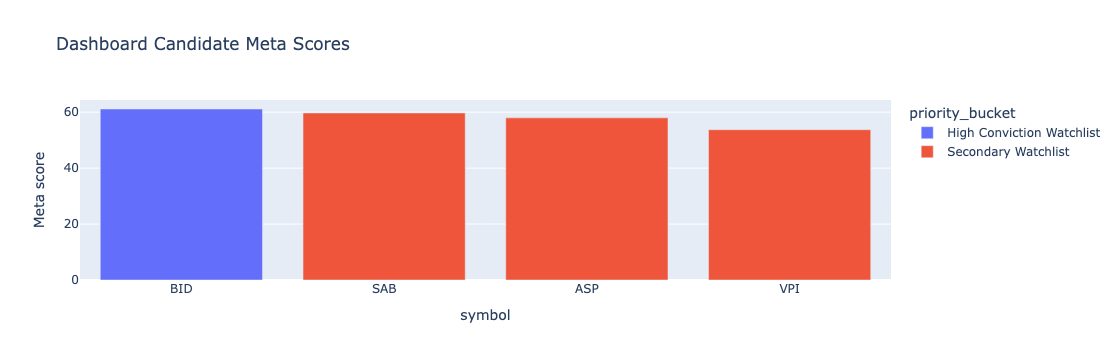

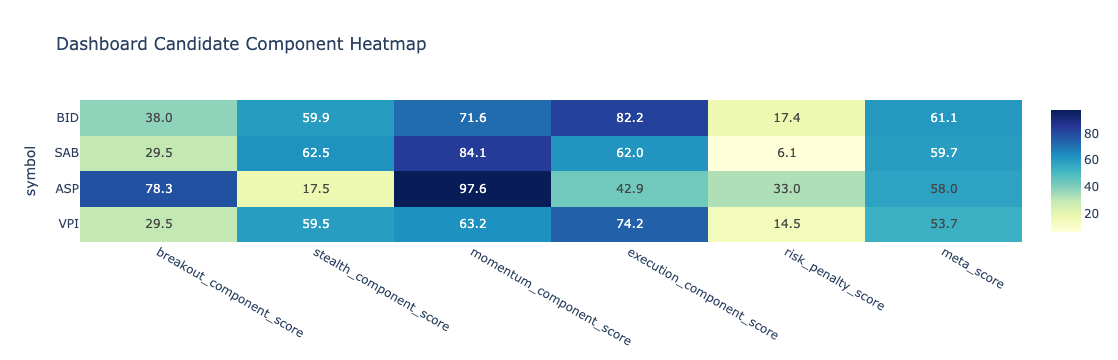

In [12]:
# Cell: Visualize Candidate Diagnostics
display(meta_score_bar_chart(candidate_source, top_n=len(candidate_source), title="Dashboard Candidate Meta Scores"))
meta_component_heatmap(candidate_source, top_n=len(candidate_source), title="Dashboard Candidate Component Heatmap")

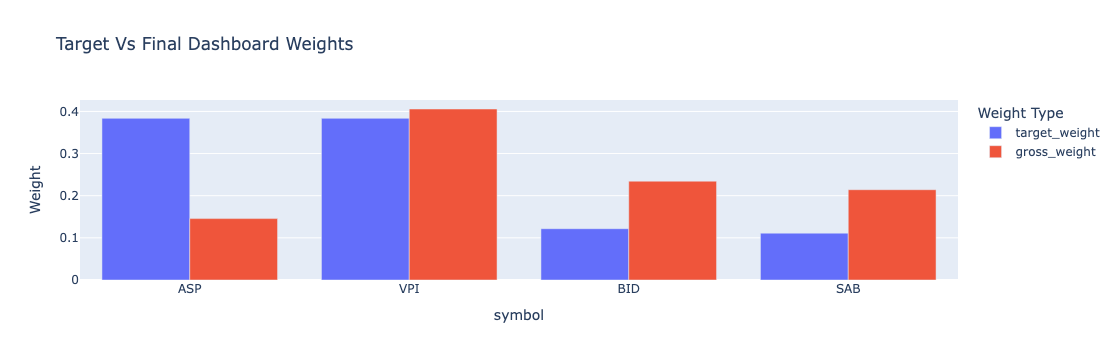

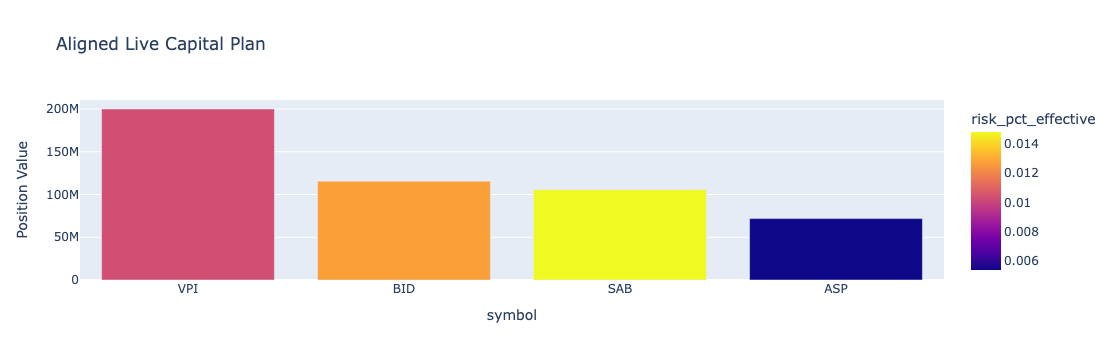

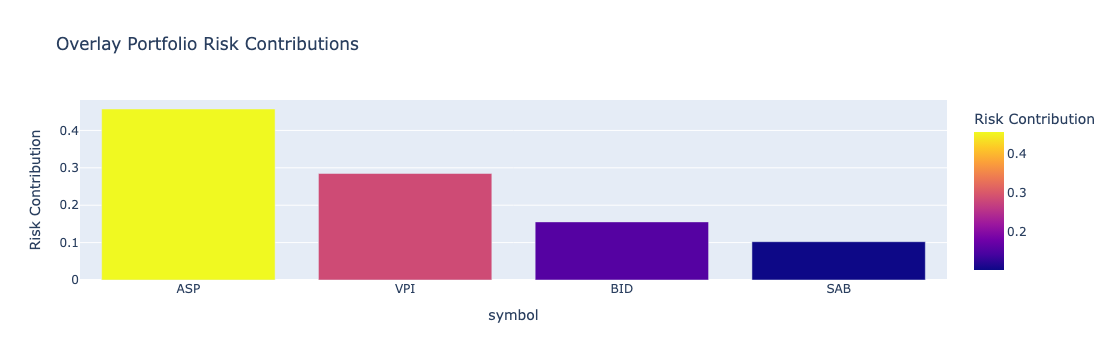

In [13]:
# Cell: Visualize Weight Alignment And Capital Plan
display(weight_comparison_chart(aligned_plan, title="Target Vs Final Dashboard Weights"))
display(capital_plan_chart(aligned_plan, value_col="position_value", title="Aligned Live Capital Plan"))
risk_contributions = portfolio_risk_contributions(overlay_weights, cov_matrix.loc[overlay_weights.index, overlay_weights.index]) if len(overlay_weights) > 1 else overlay_weights.rename("risk_contribution")
risk_contribution_chart(risk_contributions, title="Overlay Portfolio Risk Contributions")

In [14]:
# Cell: Review Portfolio NAV And Drawdown
overlay_returns = portfolio_return_series(return_matrix[overlay_weights.index.tolist()], overlay_weights)
overlay_nav = portfolio_nav_series(overlay_returns)
overlay_drawdown = rolling_drawdown(overlay_nav)

display(equity_curve_chart(overlay_nav, title="Dashboard Overlay NAV"))
drawdown_chart(overlay_drawdown, title="Dashboard Overlay Drawdown")

In [15]:
# Cell: Save Dashboard Outputs
save_parquet(candidate_source, "data/signals/live_dashboard_candidates.parquet")
save_parquet(overlay_weights.rename("target_weight").reset_index().rename(columns={"index": "symbol"}), "data/signals/risk_overlay_weights.parquet")
save_parquet(aligned_plan, "data/signals/capital_allocation_plan.parquet")
save_parquet(overlay_weights.rename("target_weight").reset_index().rename(columns={"index": "symbol"}), "data/signals/live_dashboard_weights.parquet")
save_parquet(aligned_plan, "data/signals/live_dashboard_action_plan.parquet")
print("Saved live dashboard outputs to data/signals")


Saved live dashboard outputs to data/signals
